# Placement Predictor - Starter Notebook

This notebook starts the college project using the provided train.csv, validation.csv, and test.csv files.

**What it does**
1. Loads the three CSV files.
2. Checks their columns, missing values, and placement labels.
3. Trains Logistic Regression and Random Forest models.
4. Compares models on the validation set.
5. Evaluates the selected model once on the test set.
6. Saves the trained model for the Streamlit app.



## 1. Upload the dataset files

In [1]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()

required_files = {"train.csv", "validation.csv", "test.csv"}
missing_files = required_files - set(uploaded.keys())
if missing_files:
    raise ValueError(
        f"Please upload all three files: {', '.join(sorted(missing_files))}. "
        f"Uploaded: {', '.join(uploaded.keys())}"
    )

train_df = pd.read_csv(io.BytesIO(uploaded["train.csv"]))
val_df = pd.read_csv(io.BytesIO(uploaded["validation.csv"]))
test_df = pd.read_csv(io.BytesIO(uploaded["test.csv"]))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())


Saving test.csv to test.csv
Saving train.csv to train.csv
Saving validation.csv to validation.csv
Train shape: (7225, 11)
Validation shape: (1275, 11)
Test shape: (1500, 11)


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus
0,7.7,1,1,0,69,4.0,No,No,55,69,NotPlaced
1,7.6,2,3,1,80,4.3,Yes,Yes,57,70,NotPlaced
2,7.0,1,1,1,64,4.1,No,No,58,62,NotPlaced
3,7.9,1,3,2,90,4.8,Yes,Yes,82,80,Placed
4,6.7,0,2,1,71,3.7,No,No,55,67,NotPlaced


## 2. Inspect the data

In [2]:
TARGET = "PlacementStatus"

for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\\n--- {split_name} ---")
    print("Columns:", df.columns.tolist())
    print("Missing values:", int(df.isna().sum().sum()))
    if TARGET in df.columns:
        print("Target distribution:")
        display(df[TARGET].value_counts(dropna=False).to_frame("count"))
        display((df[TARGET].value_counts(normalize=True, dropna=False) * 100)
                .round(2).to_frame("percentage"))

assert TARGET in train_df.columns, f"Target column '{TARGET}' was not found."
assert set(train_df.columns) == set(val_df.columns) == set(test_df.columns), (
    "The three files have different columns. Inspect them before continuing."
)
assert train_df[TARGET].notna().all() and val_df[TARGET].notna().all() and test_df[TARGET].notna().all(), (
    "The target column contains missing labels."
)


\n--- Train ---
Columns: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus']
Missing values: 0
Target distribution:


,count
PlacementStatus,
NotPlaced,4193
Placed,3032


,percentage
PlacementStatus,
NotPlaced,58.03
Placed,41.97


\n--- Validation ---
Columns: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus']
Missing values: 0
Target distribution:


,count
PlacementStatus,
NotPlaced,740
Placed,535


,percentage
PlacementStatus,
NotPlaced,58.04
Placed,41.96


\n--- Test ---
Columns: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks', 'PlacementStatus']
Missing values: 0
Target distribution:


,count
PlacementStatus,
NotPlaced,870
Placed,630


,percentage
PlacementStatus,
NotPlaced,58.0
Placed,42.0


## 3. Prepare features

We use `PlacementStatus` as the label to predict. The code below removes any row-ID-style columns if present, and handles numeric and categorical features with a preprocessing pipeline. It does not fit preprocessing on the validation or test data.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np
import joblib
import os

id_like = [
    col for col in train_df.columns
    if col.strip().lower() in {"id", "studentid", "student_id", "rollno", "roll_no"}
]

X_train = train_df.drop(columns=[TARGET] + id_like)
X_val = val_df.drop(columns=[TARGET] + id_like)
X_test = test_df.drop(columns=[TARGET] + id_like)

y_train_raw = train_df[TARGET].astype(str)
y_val_raw = val_df[TARGET].astype(str)
y_test_raw = test_df[TARGET].astype(str)

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)

unknown_val = set(y_val_raw.unique()) - set(label_encoder.classes_)
unknown_test = set(y_test_raw.unique()) - set(label_encoder.classes_)
if unknown_val or unknown_test:
    raise ValueError(
        f"Unseen target labels found. Validation: {unknown_val}; Test: {unknown_test}"
    )

y_val = label_encoder.transform(y_val_raw)
y_test = label_encoder.transform(y_test_raw)

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Features:", X_train.columns.tolist())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target labels:", list(label_encoder.classes_))


Features: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'ExtracurricularActivities', 'PlacementTraining', 'SSC_Marks', 'HSC_Marks']
Numeric features: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks']
Categorical features: ['ExtracurricularActivities', 'PlacementTraining']
Target labels: ['NotPlaced', 'Placed']


## 4. Train and compare two simple models

In [4]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced", random_state=42,
        n_jobs=-1, min_samples_leaf=2
    ),
}

fitted_models = {}
validation_results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipeline.fit(X_train, y_train)
    val_pred = pipeline.predict(X_val)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision (macro)": precision_score(y_val, val_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_val, val_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_val, val_pred, average="macro", zero_division=0),
    }
    validation_results.append(results)
    fitted_models[name] = pipeline

validation_table = pd.DataFrame(validation_results).sort_values(
    by="F1 (macro)", ascending=False
).reset_index(drop=True)

display(validation_table.style.format({
    "Accuracy": "{:.3f}",
    "Precision (macro)": "{:.3f}",
    "Recall (macro)": "{:.3f}",
    "F1 (macro)": "{:.3f}",
}))

best_model_name = validation_table.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print("Selected using validation macro-F1:", best_model_name)


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.791,0.787,0.793,0.788
1,Random Forest,0.792,0.787,0.785,0.786


Selected using validation macro-F1: Logistic Regression


## 5. Final evaluation on the test set

Run this after the validation comparison. The test set is used only here for the final performance estimate.

Selected model: Logistic Regression
Test accuracy: 0.784
Test precision (macro): 0.780
Test recall (macro): 0.787
Test F1 (macro): 0.781

Classification report:
              precision    recall  f1-score   support

   NotPlaced       0.84      0.77      0.81       870
      Placed       0.72      0.80      0.76       630

    accuracy                           0.78      1500
   macro avg       0.78      0.79      0.78      1500
weighted avg       0.79      0.78      0.79      1500



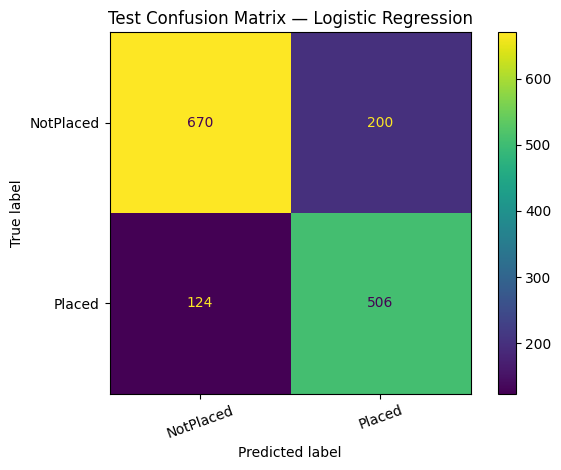

In [5]:
test_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print(f"Test accuracy: {accuracy_score(y_test, test_pred):.3f}")
print(f"Test precision (macro): {precision_score(y_test, test_pred, average='macro', zero_division=0):.3f}")
print(f"Test recall (macro): {recall_score(y_test, test_pred, average='macro', zero_division=0):.3f}")
print(f"Test F1 (macro): {f1_score(y_test, test_pred, average='macro', zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(
    y_test, test_pred, target_names=label_encoder.classes_, zero_division=0
))

cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(values_format="d")
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 6. Inspect feature importance (if supported)

In [6]:
selected_classifier = best_model.named_steps["classifier"]
fitted_preprocessor = best_model.named_steps["preprocessor"]

if hasattr(selected_classifier, "feature_importances_"):
    try:
        feature_names = fitted_preprocessor.get_feature_names_out()
        importance = pd.DataFrame({
            "Feature": feature_names,
            "Importance": selected_classifier.feature_importances_
        }).sort_values("Importance", ascending=False).head(15)

        display(importance)
        importance.sort_values("Importance").plot(
            kind="barh", x="Feature", y="Importance", legend=False,
            figsize=(9, 6)
        )
        plt.title("Top 15 Feature Importances")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("Could not display feature importance:", e)
else:
    print("The selected model does not expose tree-style feature importances.")


The selected model does not expose tree-style feature importances.


## 7. Save the model and preprocessing pipeline

In [7]:
os.makedirs("artifacts", exist_ok=True)

artifact = {
    "model": best_model,
    "label_encoder": label_encoder,
    "target_column": TARGET,
    "feature_columns": X_train.columns.tolist(),
    "selected_model_name": best_model_name,
    "validation_metrics": validation_table.to_dict(orient="records"),
}
model_path = "artifacts/placement_predictor.joblib"
joblib.dump(artifact, model_path)

print("Saved:", model_path)

from google.colab import files
files.download(model_path)


Saved: artifacts/placement_predictor.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Try one student prediction

This uses an existing test row only to demonstrate the interface. For a real new student, collect the same input fields and pass them to `best_model.predict_proba()`.

In [8]:
sample = X_test.iloc[[0]]
predicted_index = int(best_model.predict(sample)[0])
predicted_label = label_encoder.inverse_transform([predicted_index])[0]

print("Predicted placement status:", predicted_label)

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(sample)[0]
    probability_table = pd.DataFrame({
        "Placement status": label_encoder.classes_,
        "Estimated probability": probabilities
    }).sort_values("Estimated probability", ascending=False)
    display(probability_table.style.format({"Estimated probability": "{:.1%}"}))

print("Input features:")
display(sample)


Predicted placement status: Placed


,Placement status,Estimated probability
1,Placed,79.6%
0,NotPlaced,20.4%


Input features:


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks
0,7.5,2,3,3,86,4.1,Yes,Yes,69,86
